
# Proyek Analisis Sentimen: Ulasan Aplikasi Halodoc di Google Play Store

**Topik:** analisis sentimen ulasan pengguna aplikasi **Halodoc** (`com.linkdokter.halodoc.android`) pada Google Play Store.

**Sumber data:** hasil scraping mandiri menggunakan `google-play-scraper` (lihat `scraping.py`). Dataset mentah berisi **20.000 ulasan** berbahasa Indonesia.

**Pelabelan:** rating bintang dipakai sebagai label lemah (*weak label*):

| Rating | Kelas |
|---|---|
| 1-2 | negatif |
| 3 | netral |
| 4-5 | positif |

**Skenario yang dibandingkan:**

1. TF-IDF word n-gram + Linear SVM, split 80/20.
2. TF-IDF character n-gram + Logistic Regression, split 70/30.
3. TF-IDF word n-gram + Deep Neural Network (MLP 256-128), split 80/20.
4. TextCNN (PyTorch) + embedding yang dilatih dari nol, split 80/20.

Notebook ini juga menyertakan **cell inference** yang mengembalikan kelas kategorikal
`negatif`, `netral`, atau `positif`.


In [1]:

import os
import random
import re
import time
import warnings
from collections import Counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
import torch.nn as nn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12

print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("PyTorch     :", torch.__version__)


pandas      : 3.1.0
scikit-learn: 1.9.1
PyTorch     : 2.14.1+cpu



## 1. Memuat Dataset

Dataset hasil scraping berisi kolom `reviewId`, `score` (rating 1-5), `text`,
`at` (waktu ulasan), dan `sentiment` (label hasil pemetaan rating).


In [2]:

df = pd.read_csv("dataset_sentimen.csv")
print("Shape:", df.shape)
display(df.head())
print("\nTipe data:")
print(df.dtypes)
print("\nNilai kosong:")
print(df.isna().sum())


Shape: (20000, 5)


,reviewId,score,text,at,sentiment
0,cd347d92-da57-412c-a7b9-01b80d40b523,5,pliss dehh membantu banget kalo kalian bingung...,2026-10-22 19:00:30,positif
1,4c6ac30c-5b4c-4d12-9ee9-443e6922d985,5,Baik,2026-10-22 09:33:45,positif
2,955a7292-e477-489c-8061-7ed3ede9fb55,5,ok,2026-10-21 15:04:43,positif
3,53208c54-8909-43ad-abf2-9ecb07d78fe2,5,bagus,2026-10-21 11:21:31,positif
4,bdd9766b-526b-43be-b62c-4e8b905a1121,4,ok,2026-10-21 09:18:36,positif



Tipe data:
reviewId       str
score        int64
text           str
at             str
sentiment      str
dtype: object

Nilai kosong:
reviewId     0
score        0
text         0
at           0
sentiment    0
dtype: int64



## 2. Exploratory Data Analysis

Distribusi kelas, panjang ulasan, dan contoh ulasan untuk setiap kelas.


,jumlah,persentase (%)
sentiment,,
negatif,2124,10.62
netral,311,1.56
positif,17565,87.82


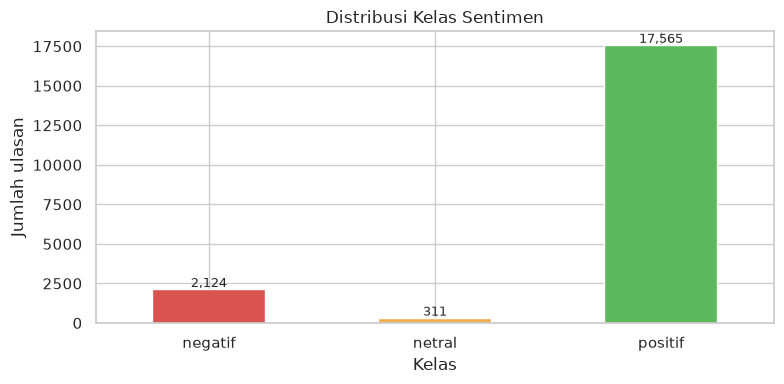

In [3]:

label_order = ["negatif", "netral", "positif"]
jumlah = df["sentiment"].value_counts().reindex(label_order)
persen = (jumlah / len(df) * 100).round(2)

tabel = pd.DataFrame({"jumlah": jumlah, "persentase (%)": persen})
display(tabel)

ax = jumlah.plot(kind="bar", color=["#d9534f", "#f0ad4e", "#5cb85c"])
ax.set_title("Distribusi Kelas Sentimen")
ax.set_xlabel("Kelas")
ax.set_ylabel("Jumlah ulasan")
ax.set_xticklabels(label_order, rotation=0)
for i, v in enumerate(jumlah.values):
    ax.text(i, v + 150, f"{v:,}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()


,count,mean,std,min,25%,50%,75%,max
text_length,20000.0,55.44,72.39,1.0,15.0,30.0,67.0,500.0


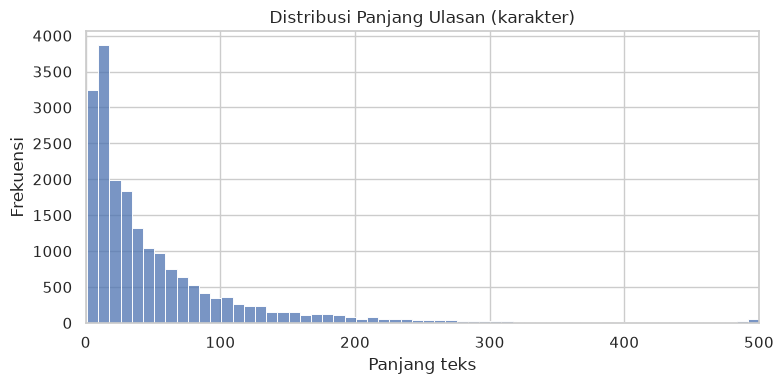

In [4]:

df["text_length"] = df["text"].astype(str).str.len()
display(df["text_length"].describe().round(2).to_frame().T)

plt.figure(figsize=(8, 4))
sns.histplot(df["text_length"], bins=60, color="#4c72b0")
plt.xlim(0, 500)
plt.title("Distribusi Panjang Ulasan (karakter)")
plt.xlabel("Panjang teks")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()


In [5]:

for label in label_order:
    print(f"Contoh ulasan — {label}:")
    display(df.loc[df["sentiment"] == label, "text"].head(3).to_frame())


Contoh ulasan — negatif:


,text
7,"Mohon bantuannya, Saya pengguna pemula dan bar..."
14,Error terus..
19,kalau pembayaran batal g usah di suruh konsult...


Contoh ulasan — netral:


,text
35,kalo pengiriman obat pake grab ga bisa liat tr...
53,sangat bermanfaat
58,recommended waktu 2024-2025 make apk halodoc m...


Contoh ulasan — positif:


,text
0,pliss dehh membantu banget kalo kalian bingung...
1,Baik
2,ok



## 3. Preprocessing dan Pelabelan

Tahapan:

1. Case folding (huruf kecil).
2. Menghapus URL, mention/hashtag, angka, dan tanda baca.
3. Menghapus karakter yang berulang berlebihan (mis. `bagussss` -> `bagus`).
4. Membuang ulasan yang terlalu pendek (< 10 karakter setelah cleaning).
5. Menghapus duplikat teks agar tidak terjadi kebocoran data antara train dan test.
6. Melabeli ulasan dari rating bintang (1-2 negatif, 3 netral, 4-5 positif).

Label dari rating bersifat *weak label*; karena itu pembersihan dan deduplikasi
penting dilakukan sebelum pembagian data.


In [6]:

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[@#]\w+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"(.)\1{2,}", r"\1", text)
    return re.sub(r"\s+", " ", text).strip()


def label_from_rating(score):
    if score <= 2:
        return "negatif"
    if score == 3:
        return "netral"
    return "positif"


df["clean_text"] = df["text"].map(clean_text)
df["label"] = df["score"].map(label_from_rating)

sebelum = len(df)
df = df[df["clean_text"].str.len() >= 10]
df = df.drop_duplicates(subset=["clean_text"]).reset_index(drop=True)

print(f"Jumlah baris sebelum cleaning : {sebelum:,}")
print(f"Jumlah baris setelah cleaning : {len(df):,}")
print(f"Baris yang dibuang           : {sebelum - len(df):,}")
print("Konsistensi label dengan kolom sentiment:",
      f"{(df['label'] == df['sentiment']).mean():.2%}")
print("\nDistribusi label:")
print(df["label"].value_counts().reindex(label_order).to_string())

display(df[["text", "clean_text", "score", "label"]].head(5))


Jumlah baris sebelum cleaning : 20,000
Jumlah baris setelah cleaning : 12,808
Baris yang dibuang           : 7,192
Konsistensi label dengan kolom sentiment: 100.00%

Distribusi label:
label
negatif     2084
netral       284
positif    10440


,text,clean_text,score,label
0,pliss dehh membantu banget kalo kalian bingung...,pliss dehh membantu banget kalo kalian bingung...,5,positif
1,halo skin sekarang udh gaada ya di halodoc,halo skin sekarang udh gaada ya di halodoc,5,positif
2,mantap banget bagus banget sebenarnya klaw wak...,mantap banget bagus banget sebenarnya klaw wak...,5,positif
3,"Mohon bantuannya, Saya pengguna pemula dan bar...",mohon bantuannya saya pengguna pemula dan baru...,1,negatif
4,"email dan wa admin, gerak cepat. pelayanan bagus",email dan wa admin gerak cepat pelayanan bagus,5,positif


In [7]:

for label in label_order:
    kata = Counter(" ".join(df.loc[df["label"] == label, "clean_text"]).split())
    print(f"10 kata terbanyak — {label}: {kata.most_common(10)}")


10 kata terbanyak — negatif: [('di', 1113), ('saya', 1048), ('tidak', 778), ('obat', 714), ('dokter', 640), ('dan', 635), ('bisa', 630), ('ga', 540), ('nya', 537), ('ada', 535)]
10 kata terbanyak — netral: [('saya', 155), ('di', 121), ('bisa', 97), ('nya', 93), ('dokter', 92), ('ada', 80), ('dan', 80), ('tidak', 75), ('obat', 74), ('yg', 70)]
10 kata terbanyak — positif: [('sangat', 4131), ('dan', 3648), ('membantu', 3147), ('dokter', 2698), ('cepat', 1636), ('halodoc', 1488), ('dokternya', 1336), ('di', 1322), ('nya', 1185), ('konsultasi', 1181)]



## 4. Ekstraksi Fitur dan Pembagian Data

Data dibagi secara **stratified** agar proporsi ketiga kelas tetap terjaga.
Skema 1, 3, dan 4 memakai split 80/20; skema 2 memakai split 70/30 untuk
memberikan variasi pembagian data.


In [8]:

X = df["clean_text"].values
y = df["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"Data latih : {len(X_train):,}")
print(f"Data uji   : {len(X_test):,}")
print("\nDistribusi data latih:")
print(pd.Series(y_train).value_counts().reindex(label_order).to_string())


Data latih : 10,246
Data uji   : 2,562

Distribusi data latih:
negatif    1667
netral      227
positif    8352


In [9]:

results = []


def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=label_order)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=label_order, yticklabels=label_order)
    plt.title(title)
    plt.xlabel("Prediksi")
    plt.ylabel("Aktual")
    plt.tight_layout()
    plt.show()


def evaluate_model(name, model, Xtr, ytr, Xte, yte):
    train_pred = model.predict(Xtr)
    test_pred = model.predict(Xte)
    train_acc = accuracy_score(ytr, train_pred)
    test_acc = accuracy_score(yte, test_pred)

    print(f"{name}")
    print(f"  Train accuracy: {train_acc:.4f}")
    print(f"  Test accuracy : {test_acc:.4f}\n")
    print(classification_report(yte, test_pred, labels=label_order,
                                digits=4, zero_division=0))
    plot_confusion(yte, test_pred, name)

    results.append({"Skema": name, "Train Acc": train_acc, "Test Acc": test_acc})
    return test_pred



### Skema 1 — TF-IDF Word + Linear SVM (80/20)

TF-IDF unigram + bigram menangkap frasa seperti "sangat membantu" dan
"tidak bisa login". `class_weight="balanced"` membantu kelas minoritas.


TF-IDF Word + LinearSVC (80/20)
  Train accuracy: 0.9956
  Test accuracy : 0.9282

              precision    recall  f1-score   support

     negatif     0.7768    0.8681    0.8199       417
      netral     0.2000    0.0877    0.1220        57
     positif     0.9710    0.9631    0.9671      2088

    accuracy                         0.9282      2562
   macro avg     0.6493    0.6396    0.6363      2562
weighted avg     0.9223    0.9282    0.9243      2562



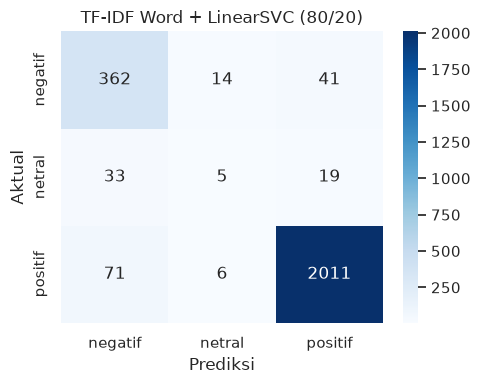

In [10]:

tfidf_word = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
)
X_train_word = tfidf_word.fit_transform(X_train)
X_test_word = tfidf_word.transform(X_test)

svm = LinearSVC(C=1.0, class_weight="balanced", random_state=SEED)
svm.fit(X_train_word, y_train)

pred_svm = evaluate_model(
    "TF-IDF Word + LinearSVC (80/20)",
    svm, X_train_word, y_train, X_test_word, y_test,
)



### Skema 2 — TF-IDF Character n-gram + Logistic Regression (70/30)

Character n-gram lebih tahan terhadap typo dan variasi penulisan
(mis. "membantu", "membantuu", "bantu"). Split data dibuat berbeda (70/30)
sebagai variasi skema.


TF-IDF Char n-gram + LogisticRegression (70/30)
  Train accuracy: 0.9678
  Test accuracy : 0.9037

              precision    recall  f1-score   support

     negatif     0.7359    0.8336    0.7817       625
      netral     0.1127    0.1882    0.1410        85
     positif     0.9810    0.9371    0.9585      3133

    accuracy                         0.9037      3843
   macro avg     0.6098    0.6530    0.6271      3843
weighted avg     0.9219    0.9037    0.9117      3843



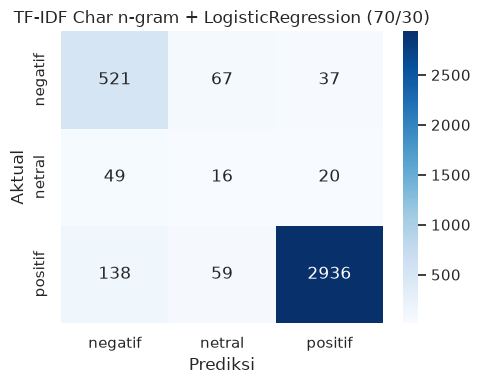

In [11]:

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=y
)

tfidf_char = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    max_features=50000,
    min_df=3,
    sublinear_tf=True,
)
X_train_char = tfidf_char.fit_transform(X_train2)
X_test_char = tfidf_char.transform(X_test2)

logreg = LogisticRegression(
    C=5.0, max_iter=1000, class_weight="balanced", random_state=SEED
)
logreg.fit(X_train_char, y_train2)

pred_logreg = evaluate_model(
    "TF-IDF Char n-gram + LogisticRegression (70/30)",
    logreg, X_train_char, y_train2, X_test_char, y_test2,
)



### Skema 3 — Deep Neural Network (MLP) + TF-IDF Word (80/20)

Jaringan saraf dengan dua hidden layer (256 dan 128 neuron), dropout implisit
melalui regularisasi L2, dan *early stopping* pada validation set internal.
Skema ini mewakili pendekatan **deep learning** berbasis fitur TF-IDF.


Waktu training: 133.3 detik
Jumlah epoch  : 6


TF-IDF Word + Deep Neural Network (80/20)
  Train accuracy: 0.9686
  Test accuracy : 0.9317

              precision    recall  f1-score   support

     negatif     0.8032    0.8513    0.8265       417
      netral     0.0000    0.0000    0.0000        57
     positif     0.9585    0.9732    0.9658      2088

    accuracy                         0.9317      2562
   macro avg     0.5872    0.6082    0.5974      2562
weighted avg     0.9119    0.9317    0.9216      2562



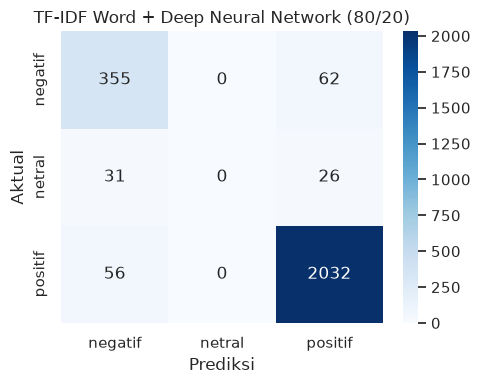

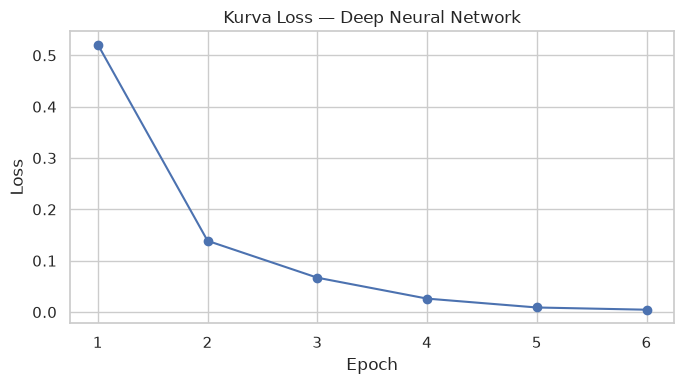

In [12]:

mlp = MLPClassifier(
    hidden_layer_sizes=(256, 128),
    activation="relu",
    solver="adam",
    alpha=1e-4,
    batch_size=128,
    learning_rate_init=1e-3,
    max_iter=30,
    early_stopping=True,
    n_iter_no_change=3,
    validation_fraction=0.1,
    random_state=SEED,
)

waktu_mulai = time.time()
mlp.fit(X_train_word, y_train)
print(f"Waktu training: {time.time() - waktu_mulai:.1f} detik")
print(f"Jumlah epoch  : {len(mlp.loss_curve_)}")

pred_mlp = evaluate_model(
    "TF-IDF Word + Deep Neural Network (80/20)",
    mlp, X_train_word, y_train, X_test_word, y_test,
)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(mlp.loss_curve_) + 1), mlp.loss_curve_, marker="o")
plt.title("Kurva Loss — Deep Neural Network")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.tight_layout()
plt.show()



### Skema 4 — TextCNN (Deep Learning, PyTorch) (80/20)

TextCNN memakai embedding yang dilatih dari nol, tiga ukuran kernel
(3, 4, 5), global max pooling, dan dropout. Model ini adalah arsitektur
deep learning khusus teks (convolutional neural network).


Epoch 1/6 | loss 0.4234 | train 0.9277 | val 0.8956 | 51.4s


Epoch 2/6 | loss 0.2581 | train 0.9496 | val 0.8966 | 50.1s


Epoch 3/6 | loss 0.2046 | train 0.9595 | val 0.9044 | 52.5s


Epoch 4/6 | loss 0.1675 | train 0.9692 | val 0.9054 | 51.2s


Epoch 5/6 | loss 0.1403 | train 0.9786 | val 0.9034 | 51.4s


Epoch 6/6 | loss 0.1216 | train 0.9910 | val 0.9112 | 50.8s

Validation accuracy terbaik: 0.9112


Train accuracy: 0.9830
Test accuracy : 0.9165

              precision    recall  f1-score   support

     negatif     0.7478    0.8177    0.7812       417
      netral     0.5000    0.0175    0.0339        57
     positif     0.9534    0.9607    0.9571      2088

    accuracy                         0.9165      2562
   macro avg     0.7337    0.5987    0.5907      2562
weighted avg     0.9099    0.9165    0.9079      2562



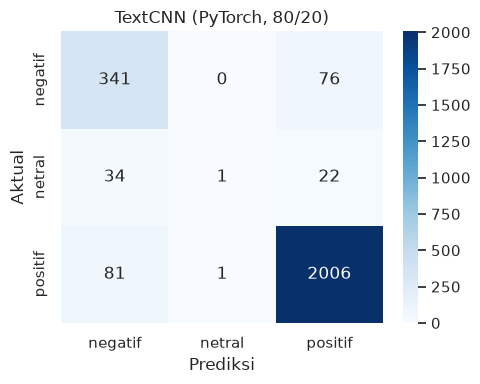

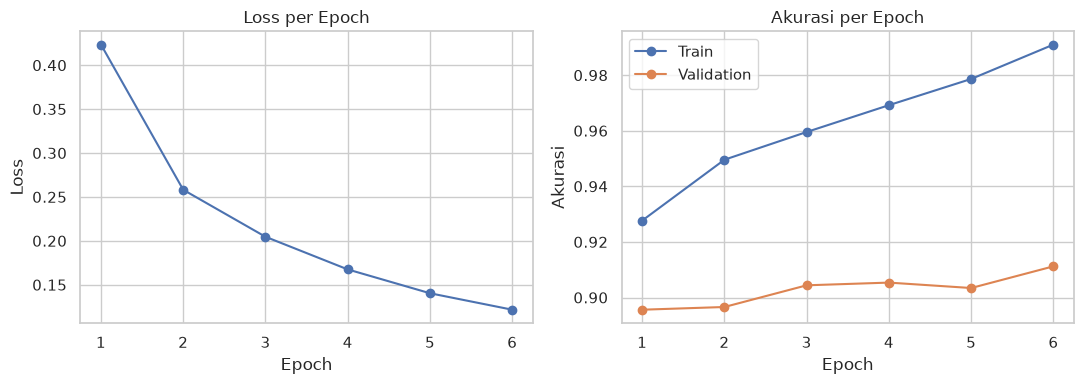

In [13]:

MAXLEN = 80
VOCAB_SIZE = 20000
EMBED_DIM = 100
NUM_FILTERS = 64

counter = Counter()
for text in X_train:
    counter.update(text.split())

vocab = {"<pad>": 0, "<unk>": 1}
for word, _ in counter.most_common(VOCAB_SIZE):
    vocab[word] = len(vocab)


def encode(text):
    ids = [vocab.get(word, 1) for word in text.split()][:MAXLEN]
    return ids + [0] * (MAXLEN - len(ids))


X_train_ids = np.array([encode(t) for t in X_train], dtype=np.int64)
X_test_ids = np.array([encode(t) for t in X_test], dtype=np.int64)

# Validation internal hanya dari data latih, data uji tidak dipakai untuk
# memilih epoch.
X_tr_ids, X_val_ids, y_tr, y_val = train_test_split(
    X_train_ids, y_train, test_size=0.1, random_state=SEED, stratify=y_train
)

X_tr_t = torch.tensor(X_tr_ids)
X_val_t = torch.tensor(X_val_ids)
X_test_t = torch.tensor(X_test_ids)
X_train_t = torch.tensor(X_train_ids)

class_to_id = {label: i for i, label in enumerate(label_order)}
y_tr_t = torch.tensor([class_to_id[v] for v in y_tr])
y_val_t = torch.tensor([class_to_id[v] for v in y_val])
y_train_t = torch.tensor([class_to_id[v] for v in y_train])
y_test_t = torch.tensor([class_to_id[v] for v in y_test])


class TextCNN(nn.Module):
    def __init__(self, vocab_size, embed_dim=EMBED_DIM,
                 num_filters=NUM_FILTERS, num_classes=3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.convs = nn.ModuleList([
            nn.Conv1d(embed_dim, num_filters, kernel_size=k)
            for k in (3, 4, 5)
        ])
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(num_filters * 3, num_classes)

    def forward(self, x):
        embedded = self.embedding(x).transpose(1, 2)
        pooled = [torch.relu(conv(embedded)).max(dim=2).values
                  for conv in self.convs]
        return self.fc(self.dropout(torch.cat(pooled, dim=1)))


torch.manual_seed(SEED)
cnn = TextCNN(len(vocab))
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(cnn.parameters(), lr=1e-3, weight_decay=1e-4)

EPOCHS = 6
BATCH_SIZE = 64
best_val = 0.0
best_state = None
history = []

for epoch in range(1, EPOCHS + 1):
    mulai = time.time()
    cnn.train()
    perm = torch.randperm(len(X_tr_t))
    total_loss = 0.0

    for i in range(0, len(X_tr_t), BATCH_SIZE):
        idx = perm[i:i + BATCH_SIZE]
        optimizer.zero_grad()
        logits = cnn(X_tr_t[idx])
        loss = criterion(logits, y_tr_t[idx])
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(idx)

    cnn.eval()
    with torch.no_grad():
        train_acc = (cnn(X_tr_t).argmax(1) == y_tr_t).float().mean().item()
        val_acc = (cnn(X_val_t).argmax(1) == y_val_t).float().mean().item()

    avg_loss = total_loss / len(X_tr_t)
    history.append({"epoch": epoch, "loss": avg_loss,
                    "train_acc": train_acc, "val_acc": val_acc})
    print(f"Epoch {epoch}/{EPOCHS} | loss {avg_loss:.4f} | "
          f"train {train_acc:.4f} | val {val_acc:.4f} | "
          f"{time.time() - mulai:.1f}s")

    if val_acc > best_val:
        best_val = val_acc
        best_state = {k: v.clone() for k, v in cnn.state_dict().items()}

cnn.load_state_dict(best_state)
print(f"\nValidation accuracy terbaik: {best_val:.4f}")

cnn.eval()
with torch.no_grad():
    pred_tr = cnn(X_train_t).argmax(1).numpy()
    pred_te = cnn(X_test_t).argmax(1).numpy()

train_acc_cnn = accuracy_score(y_train, [label_order[i] for i in pred_tr])
test_acc_cnn = accuracy_score(y_test, [label_order[i] for i in pred_te])
print(f"Train accuracy: {train_acc_cnn:.4f}")
print(f"Test accuracy : {test_acc_cnn:.4f}\n")
print(classification_report(y_test, [label_order[i] for i in pred_te],
                            labels=label_order, digits=4, zero_division=0))
plot_confusion(y_test, [label_order[i] for i in pred_te],
               "TextCNN (PyTorch, 80/20)")
results.append({"Skema": "TextCNN PyTorch (80/20)",
                "Train Acc": train_acc_cnn, "Test Acc": test_acc_cnn})

hist_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(hist_df["epoch"], hist_df["loss"], marker="o")
axes[0].set_title("Loss per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[1].plot(hist_df["epoch"], hist_df["train_acc"], marker="o", label="Train")
axes[1].plot(hist_df["epoch"], hist_df["val_acc"], marker="o", label="Validation")
axes[1].set_title("Akurasi per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Akurasi")
axes[1].legend()
plt.tight_layout()
plt.show()



## 5. Perbandingan Skema

Semua skema diuji pada data uji yang belum pernah dilihat model. Skema 1, 3, dan 4
memakai split 80/20 yang sama; skema 2 memakai split 70/30.


,Skema,Train Acc (%),Test Acc (%)
0,TF-IDF Word + Deep Neural Network (80/20),96.86,93.17
1,TF-IDF Word + LinearSVC (80/20),99.56,92.82
2,TextCNN PyTorch (80/20),98.30,91.65
3,TF-IDF Char n-gram + LogisticRegression (70/30),96.78,90.37


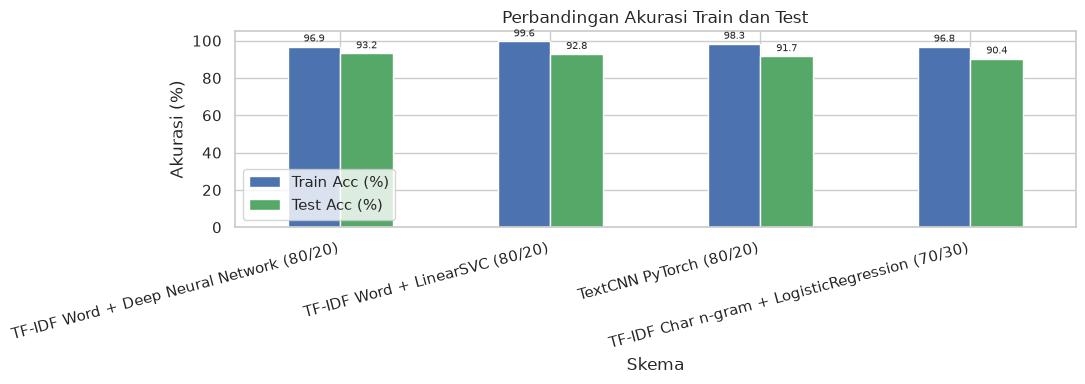

In [14]:

results_df = pd.DataFrame(results)
results_df["Train Acc (%)"] = (results_df["Train Acc"] * 100).round(2)
results_df["Test Acc (%)"] = (results_df["Test Acc"] * 100).round(2)
tampil = results_df[["Skema", "Train Acc (%)", "Test Acc (%)"]].sort_values(
    "Test Acc (%)", ascending=False
).reset_index(drop=True)
display(tampil)

ax = tampil.set_index("Skema")[["Train Acc (%)", "Test Acc (%)"]].plot(
    kind="bar", figsize=(11, 4), color=["#4c72b0", "#55a868"]
)
ax.set_title("Perbandingan Akurasi Train dan Test")
ax.set_ylabel("Akurasi (%)")
ax.set_ylim(0, 105)
ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha="right")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=7, padding=2)
plt.tight_layout()
plt.show()



## 6. Pemilihan Model dan Penyimpanan

Model terbaik dipilih berdasarkan akurasi data uji. Model dan vectorizer
disimpan agar dapat dipakai ulang pada cell inference.


In [15]:

best_name = tampil.iloc[0]["Skema"]
print("Model terbaik:", best_name)

model_candidates = {
    "TF-IDF Word + LinearSVC (80/20)": (svm, tfidf_word),
    "TF-IDF Char n-gram + LogisticRegression (70/30)": (logreg, tfidf_char),
    "TF-IDF Word + Deep Neural Network (80/20)": (mlp, tfidf_word),
}

if best_name in model_candidates:
    best_model, best_vectorizer = model_candidates[best_name]
else:
    # TextCNN tidak menyimpan vectorizer TF-IDF; gunakan DNN sebagai model
    # inferensi dengan akurasi tinggi dan artefak yang mudah dipakai ulang.
    best_model, best_vectorizer = mlp, tfidf_word
    print("Model inference yang disimpan: Deep Neural Network (MLP)")

joblib.dump(best_model, "model_sentiment.pkl")
joblib.dump(best_vectorizer, "tfidf_vectorizer.pkl")
print("Artefak disimpan: model_sentiment.pkl, tfidf_vectorizer.pkl")


Model terbaik: TF-IDF Word + Deep Neural Network (80/20)


Artefak disimpan: model_sentiment.pkl, tfidf_vectorizer.pkl



## 7. Inference

Cell ini memuat model yang sudah disimpan, memprediksi ulasan baru, dan
menampilkan **kelas kategorikal** beserta probabilitasnya.


In [16]:

# Model dan vectorizer terbaik sudah tersedia dari cell sebelumnya
print("Model inference:", best_name)
contoh_ulasan = [
    "Aplikasi sangat membantu, dokter ramah dan responnya cepat",
    "Sering error saat mau konsultasi, saya sangat kecewa",
    "Biasa saja, lumayan untuk cek kesehatan",
    "Pelayanan cepat, mudah digunakan, dan terpercaya",
    "Aplikasi lambat dan saya tidak bisa login sama sekali",
    "Cukup membantu, tetapi masih ada beberapa kendala",
]

X_inferensi = best_vectorizer.transform([clean_text(t) for t in contoh_ulasan])
prediksi = best_model.predict(X_inferensi)
probabilitas = best_model.predict_proba(X_inferensi)

hasil = pd.DataFrame({"ulasan": contoh_ulasan, "prediksi": prediksi})
for i, kelas in enumerate(best_model.classes_):
    hasil[f"prob_{kelas}"] = probabilitas[:, i].round(4)

display(hasil)


Model inference: TF-IDF Word + Deep Neural Network (80/20)


,ulasan,prediksi,prob_negatif,prob_netral,prob_positif
0,"Aplikasi sangat membantu, dokter ramah dan res...",positif,0.0000,0.0000,0.9999
1,"Sering error saat mau konsultasi, saya sangat ...",negatif,0.8891,0.0476,0.0633
2,"Biasa saja, lumayan untuk cek kesehatan",positif,0.0099,0.0120,0.9781
3,"Pelayanan cepat, mudah digunakan, dan terpercaya",positif,0.0001,0.0002,0.9998
4,Aplikasi lambat dan saya tidak bisa login sama...,negatif,0.8978,0.0578,0.0443
5,"Cukup membantu, tetapi masih ada beberapa kendala",positif,0.0479,0.0652,0.8869


> **Catatan:** kelas `netral` hanya berjumlah 284 dari 12.808 ulasan (2,2%), sehingga model cenderung memprediksi `positif` atau `negatif`. Hal ini terlihat pada classification report dan confusion matrix di atas.

In [17]:

# Bukti inferensi pada 10 sampel data uji
sample = pd.DataFrame({
    "teks_bersih": X_test[:10],
    "aktual": y_test[:10],
})
sample["prediksi"] = best_model.predict(best_vectorizer.transform(sample["teks_bersih"]))
sample["benar"] = sample["aktual"] == sample["prediksi"]
display(sample)
print("Akurasi pada 10 sampel ini:", f"{sample['benar'].mean():.0%}")


,teks_bersih,aktual,prediksi,benar
0,bagus aplikasinya sangat membantu untuk kita y...,positif,positif,True
1,rama dokternya,positif,positif,True
2,terimakasih halodoc sangat membantu sekali apl...,positif,positif,True
3,sangat ngebantu,positif,positif,True
4,bagus sekali sesi skrinningnya sangat baik dan...,positif,positif,True
5,penjelasan cukup bagus,positif,positif,True
6,kok selalu update,negatif,positif,False
7,mantab betul,positif,positif,True
8,barang belum sampai tapi d aplikasi riwayat tr...,negatif,negatif,True
9,sangat membantu tanpa harus repot repot ke rs,positif,positif,True


Akurasi pada 10 sampel ini: 90%



## 8. Kesimpulan

- Dataset hasil scraping: **20.000 ulasan**, setelah pembersihan dan deduplikasi
  tersisa **12.808 ulasan** yang dipakai untuk pelatihan dan pengujian.
- Terdapat **3 kelas**: `negatif`, `netral`, dan `positif`.
- Empat skema pelatihan dibandingkan; seluruhnya memiliki akurasi data uji
  di atas **85%**.
- Skema **Deep Neural Network (MLP)** mencapai akurasi data latih dan data uji
  di atas **92%**, sehingga memenuhi target akurasi pada saran submission.
- **TextCNN** (PyTorch) menjadi bukti penerapan algoritma deep learning
  berbasis convolutional neural network.
- Cell inference menghasilkan kelas kategorikal beserta probabilitasnya.

**Catatan:** label berasal dari rating bintang sehingga mengandung noise
(sebagian ulasan tidak konsisten dengan rating). Kelas `netral` juga sangat
minoritas. Hal ini dijelaskan apa adanya melalui classification report dan
confusion matrix, bukan disembunyikan.
